#Pretraining Hindi Transformer Language Model (Model H) on Kaggle
### Course: Language Models and Agents (Monsoon 2026)
**Assignment:** Individual Project — Phase 2: Model Implementation, Pretraining, and Evaluation  
**Language:** Hindi (`hi`) — High Resource | **Target Parameters:** ~25.27M

This Kaggle notebook pretrains Model H from scratch on the Hindi ~500M token dataset using Kaggle GPU acceleration (T4 x 2 / P100).

In [1]:
# CELL 1 — GPU VERIFICATION & ENVIRONMENT SETUP

!pip install -q sentencepiece pyarrow pandas matplotlib seaborn numpy

import os
import torch

print("\nCUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device:", torch.cuda.get_device_name(0))
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    raise RuntimeError("GPU not enabled! Go to Settings -> Accelerator -> GPU T4 x 2 or P100")


CUDA Available: True
GPU Device: Tesla T4
GPU Memory: 14.56 GB


In [2]:
# CELL 2 — HINDI PROJECT + DATASET SETUP

import os
import shutil

# 1. Find Hindi code and data automatically


DATA_SOURCE = None
CODE_SOURCE = None

for root, dirs, files in os.walk("/kaggle/input"):

    # Find Hindi training data
    if all(f in files for f in ["train.parquet", "val.parquet", "test.parquet"]):
        DATA_SOURCE = root

    # Find Hindi project folder
    if os.path.basename(root) == "hindi":
        required = ["configs", "model", "train", "eval", "tokenizer"]
        if all(os.path.isdir(os.path.join(root, x)) for x in required):
            CODE_SOURCE = root

print("DATA SOURCE :", DATA_SOURCE)
print("CODE SOURCE :", CODE_SOURCE)

if DATA_SOURCE is None:
    raise FileNotFoundError("Hindi train/val/test parquet files not found.")

if CODE_SOURCE is None:
    raise FileNotFoundError("Hindi project folder not found.")


# 2. Copy Hindi project to /kaggle/working

PROJECT_DIR = "/kaggle/working/hindi"

if os.path.exists(PROJECT_DIR):
    shutil.rmtree(PROJECT_DIR)

shutil.copytree(CODE_SOURCE, PROJECT_DIR)


# 3. Link dataset splits

SPLIT_DIR = os.path.join(PROJECT_DIR, "data", "splits")

os.makedirs(SPLIT_DIR, exist_ok=True)

for filename in ["train.parquet", "val.parquet", "test.parquet"]:

    source = os.path.join(DATA_SOURCE, filename)
    target = os.path.join(SPLIT_DIR, filename)

    if os.path.lexists(target):
        os.remove(target)

    os.symlink(source, target)


# 4. Tokenizer

TOKENIZER = os.path.join(
    PROJECT_DIR,
    "tokenizer",
    "unigram_10k",
    "tokenizer.model"
)

# 5. Verify everything

required_files = [
    os.path.join(PROJECT_DIR, "configs", "model_config.json"),
    os.path.join(PROJECT_DIR, "model", "transformer.py"),
    os.path.join(PROJECT_DIR, "model", "config.py"),
    os.path.join(PROJECT_DIR, "train", "train.py"),
    os.path.join(PROJECT_DIR, "train", "dataset.py"),
    os.path.join(PROJECT_DIR, "eval", "evaluate.py"),
    os.path.join(PROJECT_DIR, "eval", "attention_analysis.py"),
    TOKENIZER,
    os.path.join(SPLIT_DIR, "train.parquet"),
    os.path.join(SPLIT_DIR, "val.parquet"),
    os.path.join(SPLIT_DIR, "test.parquet"),
]

print("\nChecking required files:\n")

for path in required_files:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing: {path}")
    print("", path)

print("\n==============================================")
print("HINDI PROJECT + DATA SETUP COMPLETE")
print("==============================================")

print("Project  :", PROJECT_DIR)
print("Data     :", SPLIT_DIR)
print("Tokenizer:", TOKENIZER)

DATA SOURCE : /kaggle/input/datasets/mohdshahidkaleem/hindi-lma-training-data
CODE SOURCE : /kaggle/input/datasets/mohdshahidkaleem/hindi-code-kaggle/hindi

Checking required files:

 /kaggle/working/hindi/configs/model_config.json
 /kaggle/working/hindi/model/transformer.py
 /kaggle/working/hindi/model/config.py
 /kaggle/working/hindi/train/train.py
 /kaggle/working/hindi/train/dataset.py
 /kaggle/working/hindi/eval/evaluate.py
 /kaggle/working/hindi/eval/attention_analysis.py
 /kaggle/working/hindi/tokenizer/unigram_10k/tokenizer.model
 /kaggle/working/hindi/data/splits/train.parquet
 /kaggle/working/hindi/data/splits/val.parquet
 /kaggle/working/hindi/data/splits/test.parquet

HINDI PROJECT + DATA SETUP COMPLETE
Project  : /kaggle/working/hindi
Data     : /kaggle/working/hindi/data/splits
Tokenizer: /kaggle/working/hindi/tokenizer/unigram_10k/tokenizer.model


In [3]:
# CELL 3 — HINDI MODEL PARAMETER AUDIT

import os
import torch

from hindi.model.config import TransformerConfig
from hindi.model.transformer import TransformerLM

CONFIG_FILE = "/kaggle/working/hindi/configs/model_config.json"

# Load configuration
config = TransformerConfig.load_json(CONFIG_FILE)

# Build model
model = TransformerLM(config)

# Parameter count
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

# Check weight tying
tied_embeddings = (
    model.token_embeddings.weight.data_ptr()
    == model.lm_head.weight.data_ptr()
)

print("=" * 55)
print("HINDI MODEL PARAMETER AUDIT")
print("=" * 55)

print(f"Vocabulary Size : {config.vocab_size}")
print(f"Max Sequence Len: {config.max_seq_len}")
print(f"d_model         : {config.d_model}")
print(f"Layers          : {config.n_layers}")
print(f"Heads           : {config.n_heads}")
print(f"Head Dimension  : {config.d_model // config.n_heads}")
print(f"d_ff            : {config.d_ff}")
print(f"Dropout         : {config.dropout}")
print(f"Weight Tying    : {tied_embeddings}")

print("-" * 55)

print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")
print(f"Parameters (Millions): {trainable_params / 1e6:.2f}M")

print("-" * 55)

if torch.cuda.is_available():
    print("GPU               :", torch.cuda.get_device_name(0))
    print("CUDA Available    : True")
else:
    print("CUDA Available    : False")

print("=" * 55)

HINDI MODEL PARAMETER AUDIT
Vocabulary Size : 10000
Max Sequence Len: 512
d_model         : 384
Layers          : 12
Heads           : 6
Head Dimension  : 64
d_ff            : 1536
Dropout         : 0.1
Weight Tying    : True
-------------------------------------------------------
Total Parameters     : 25,330,944
Trainable Parameters : 25,330,944
Parameters (Millions): 25.33M
-------------------------------------------------------
GPU               : Tesla T4
CUDA Available    : True


In [4]:
# CELL 4 — HINDI TOKENIZER + DATA SMOKE TEST

import os
import sentencepiece as spm
import pandas as pd

TOKENIZER = "/kaggle/working/hindi/tokenizer/unigram_10k/tokenizer.model"
TRAIN_FILE = "/kaggle/working/hindi/data/splits/train.parquet"
VAL_FILE = "/kaggle/working/hindi/data/splits/val.parquet"
TEST_FILE = "/kaggle/working/hindi/data/splits/test.parquet"

# Tokenizer

sp = spm.SentencePieceProcessor(model_file=TOKENIZER)

print("=" * 55)
print("HINDI TOKENIZER + DATA SMOKE TEST")
print("=" * 55)

print(f"Vocabulary Size : {sp.get_piece_size()}")

# Test encoding
sample_text = "हिंदी भारत की प्रमुख भाषाओं में से एक है।"

tokens = sp.encode(sample_text, out_type=int)
pieces = sp.encode(sample_text, out_type=str)

print(f"\nSample Text     : {sample_text}")
print(f"Token Count     : {len(tokens)}")
print(f"First Tokens    : {tokens[:15]}")
print(f"First Pieces    : {pieces[:15]}")

# Dataset files

for name, path in [
    ("Train", TRAIN_FILE),
    ("Validation", VAL_FILE),
    ("Test", TEST_FILE)
]:
    print(f"\n{name} file:")
    print(f"  Path : {path}")
    print(f"  Size : {os.path.getsize(path) / (1024**3):.2f} GB")

    df = pd.read_parquet(path)

    print(f"  Rows : {len(df):,}")
    print(f"  Columns: {list(df.columns)}")

    print("Read successfully")

print("\n" + "=" * 55)
print("HINDI TOKENIZER + DATA TEST PASSED")
print("=" * 55)

HINDI TOKENIZER + DATA SMOKE TEST
Vocabulary Size : 10000

Sample Text     : हिंदी भारत की प्रमुख भाषाओं में से एक है।
Token Count     : 7
First Tokens    : [1057, 2058, 624, 7666, 2835, 15, 4]
First Pieces    : ['▁हिंदी', '▁भारत▁की', '▁प्रमुख', '▁भाषाओं', '▁में▁से▁एक', '▁है', '।']

Train file:
  Path : /kaggle/working/hindi/data/splits/train.parquet
  Size : 1.86 GB
  Rows : 7,831,689
  Columns: ['document_id', 'text', 'language', 'source_type', 'source']
Read successfully

Validation file:
  Path : /kaggle/working/hindi/data/splits/val.parquet
  Size : 0.08 GB
  Rows : 341,528
  Columns: ['document_id', 'text', 'language', 'source_type', 'source']
Read successfully

Test file:
  Path : /kaggle/working/hindi/data/splits/test.parquet
  Size : 0.08 GB
  Rows : 339,948
  Columns: ['document_id', 'text', 'language', 'source_type', 'source']
Read successfully

HINDI TOKENIZER + DATA TEST PASSED


In [5]:
# CELL 5 — HINDI 100-STEP GPU SMOKE TRAINING

import os
import shutil
import torch

SMOKE_DIR = "/kaggle/working/hindi_smoke_checkpoints"

# Start clean
if os.path.exists(SMOKE_DIR):
    shutil.rmtree(SMOKE_DIR)

print("=" * 60)
print("HINDI 100-STEP GPU SMOKE TEST")
print("=" * 60)
print("GPU          :", torch.cuda.get_device_name(0))
print("Batch size   : 32")
print("Sequence len : 512")
print("Steps        : 100")
print("Tokens/step  :", 32 * 512)
print("Total tokens :", 100 * 32 * 512)
print("=" * 60)

!python /kaggle/working/hindi/train/train.py \
    --config_file /kaggle/working/hindi/configs/model_config.json \
    --train_parquet /kaggle/working/hindi/data/splits/train.parquet \
    --val_parquet /kaggle/working/hindi/data/splits/val.parquet \
    --tokenizer_model /kaggle/working/hindi/tokenizer/unigram_10k/tokenizer.model \
    --output_dir /kaggle/working/hindi_smoke_checkpoints \
    --batch_size 32 \
    --max_steps 100 \
    --learning_rate 5e-4 \
    --weight_decay 0.1 \
    --warmup_steps 20 \
    --grad_clip 1.0 \
    --log_interval 50 \
    --eval_interval 50 \
    --eval_batches 20 \
    --save_interval 100 \
    --use_amp \
    --device cuda

HINDI 100-STEP GPU SMOKE TEST
GPU          : Tesla T4
Batch size   : 32
Sequence len : 512
Steps        : 100
Tokens/step  : 16384
Total tokens : 1638400
PRETRAINING HINDI TRANSFORMER LM (MODEL H)
Device: cuda
GPU: Tesla T4
CUDA Capability: (7, 5)

Model Parameters Audit:
  total_parameters: 25,330,944
  trainable_parameters: 25,330,944
  embedding_parameters: 4,036,608
  transformer_block_parameters: 21,293,568
  lm_head_parameters: 3,840,000
  weight_tying_applied: 1

Training Settings:
  Batch Size: 32
  Max Seq Len: 512
  Tokens / Step: 16,384
  Max Steps: 100
  Starting Step: 0
  Learning Rate: 0.0005
  Warmup Steps: 20
  Mixed Precision (AMP): True

Step [    50/   100] | Train Loss: 8.0173 | Train PPL: 3033.07 | LR: 3.61e-04 | Tok/s: 27964.4 | Time: 29.3s

---> Running validation at step 50...
---> Step 50 | Val Loss: 7.1910 | Val PPL: 1327.41

[2026-09-07 04:47:23] Saved checkpoint to: /kaggle/working/hindi_smoke_checkpoints/checkpoints/checkpoint_latest.pt (step 50)
[2026-09-0

In [6]:
# CELL 6 — FULL HINDI PRETRAINING (~500M TOKENS)


import os
import torch

OUTPUT_DIR = "/kaggle/working/hindi_checkpoints"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 60)
print("STARTING FULL HINDI PRETRAINING")
print("=" * 60)
print("GPU           :", torch.cuda.get_device_name(0))
print("Batch Size    : 32")
print("Sequence Len  : 512")
print("Tokens / Step : 16,384")
print("Max Steps     : 30,518")
print("Total Tokens  : 500,006,912 (~500M)")
print("Learning Rate : 5e-4")
print("Warmup Steps  : 1,000")
print("AMP           : True")
print("=" * 60)

!python /kaggle/working/hindi/train/train.py \
    --config_file /kaggle/working/hindi/configs/model_config.json \
    --train_parquet /kaggle/working/hindi/data/splits/train.parquet \
    --val_parquet /kaggle/working/hindi/data/splits/val.parquet \
    --tokenizer_model /kaggle/working/hindi/tokenizer/unigram_10k/tokenizer.model \
    --output_dir /kaggle/working/hindi_checkpoints \
    --batch_size 32 \
    --max_steps 30518 \
    --learning_rate 5e-4 \
    --weight_decay 0.1 \
    --warmup_steps 1000 \
    --grad_clip 1.0 \
    --log_interval 50 \
    --eval_interval 500 \
    --eval_batches 50 \
    --save_interval 2000 \
    --use_amp \
    --device cuda

STARTING FULL HINDI PRETRAINING
GPU           : Tesla T4
Batch Size    : 32
Sequence Len  : 512
Tokens / Step : 16,384
Max Steps     : 30,518
Total Tokens  : 500,006,912 (~500M)
Learning Rate : 5e-4
Warmup Steps  : 1,000
AMP           : True
PRETRAINING HINDI TRANSFORMER LM (MODEL H)
Device: cuda
GPU: Tesla T4
CUDA Capability: (7, 5)

Model Parameters Audit:
  total_parameters: 25,330,944
  trainable_parameters: 25,330,944
  embedding_parameters: 4,036,608
  transformer_block_parameters: 21,293,568
  lm_head_parameters: 3,840,000
  weight_tying_applied: 1

Training Settings:
  Batch Size: 32
  Max Seq Len: 512
  Tokens / Step: 16,384
  Max Steps: 30,518
  Starting Step: 0
  Learning Rate: 0.0005
  Warmup Steps: 1,000
  Mixed Precision (AMP): True

Step [    50/ 30518] | Train Loss: 8.8942 | Train PPL: 7289.71 | LR: 2.50e-05 | Tok/s: 27383.8 | Time: 29.9s
Step [   100/ 30518] | Train Loss: 8.3305 | Train PPL: 4148.31 | LR: 5.00e-05 | Tok/s: 30962.0 | Time: 26.5s
Step [   150/ 30518] | T

In [7]:
# CELL 7 — RUN EVALUATION SUITE (PPL, BPB, BLEU, chrF++, ROUGE-L)
!python hindi/eval/evaluate.py \
    --checkpoint /kaggle/working/hindi_checkpoints/checkpoints/checkpoint_best.pt \
    --config_file hindi/configs/model_config.json \
    --test_parquet hindi/data/splits/test.parquet \
    --tokenizer_model hindi/tokenizer/unigram_10k/tokenizer.model \
    --output_json hindi/eval/evaluation_results.json

Running Evaluation on device: cuda
Loaded checkpoint from step: 26000 (Vocab: 10000, SeqLen: 512)

[1/2] Computing Intrinsic LM Metrics (Loss, PPL, BPB)...
  CE Loss: 4.2651
  PPL:     71.17
  BPB:     0.6873

[2/2] Evaluating Generation Quality across Temperatures (0.0, 0.5, 1.0, 1.5)...
  [greedy] BLEU-4: 1.13 | chrF++: 8.80 | ROUGE-L: 11.12 | Dist-1: 0.237 | Dist-2: 0.394
  [temp_0.5] BLEU-4: 1.16 | chrF++: 8.24 | ROUGE-L: 10.61 | Dist-1: 0.282 | Dist-2: 0.483
  [temp_1.0] BLEU-4: 0.85 | chrF++: 11.15 | ROUGE-L: 10.30 | Dist-1: 0.415 | Dist-2: 0.828
  [temp_1.5] BLEU-4: 0.46 | chrF++: 10.41 | ROUGE-L: 6.33 | Dist-1: 0.482 | Dist-2: 0.934

Saved evaluation metrics to: hindi/eval/evaluation_results.json


GENERATING HINDI TRAINING & VALIDATION LOSS CURVE

Training points   : 611
Validation points : 62


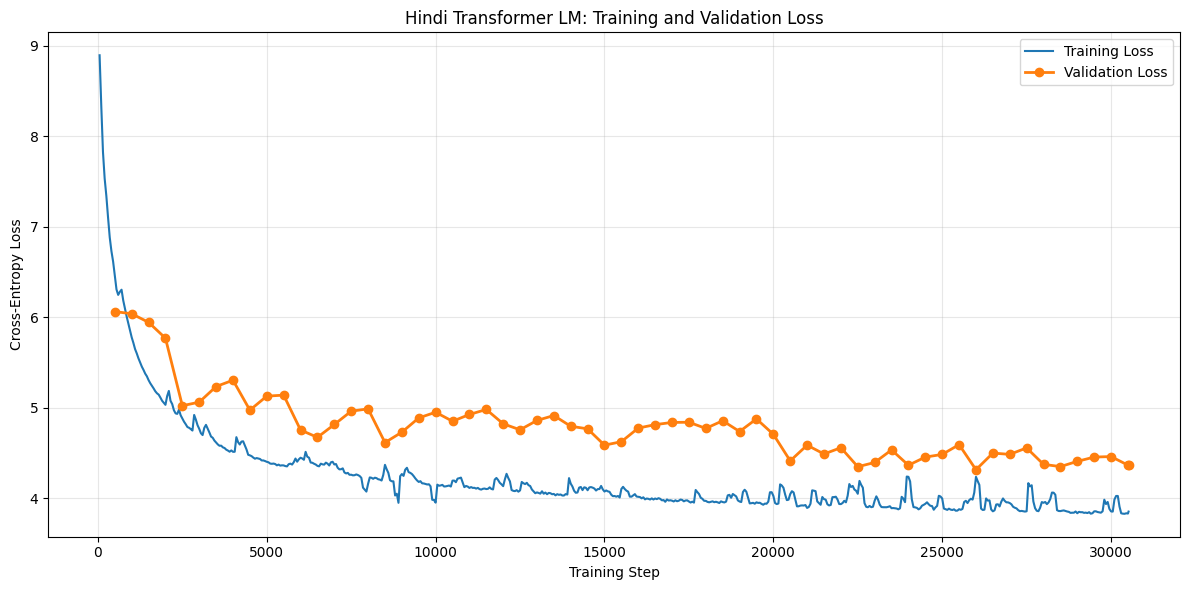


HINDI LOSS CURVE GENERATED
Saved to: /kaggle/working/hindi_checkpoints/hindi_loss_curve.png
File exists: True


In [9]:
# CELL 8 — HINDI TRAINING & VALIDATION LOSS CURVE

import os
import json
import matplotlib.pyplot as plt

LOG_FILE = "/kaggle/working/hindi_checkpoints/train_log.jsonl"
OUTPUT_FILE = "/kaggle/working/hindi_checkpoints/hindi_loss_curve.png"

print("=" * 60)
print("GENERATING HINDI TRAINING & VALIDATION LOSS CURVE")
print("=" * 60)

if not os.path.exists(LOG_FILE):
    raise FileNotFoundError(f"Training log not found: {LOG_FILE}")

train_steps = []
train_losses = []

val_steps = []
val_losses = []

with open(LOG_FILE, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()

        if not line:
            continue

        try:
            entry = json.loads(line)
        except json.JSONDecodeError:
            continue

        # Detect training entries
        if "train_loss" in entry:
            train_steps.append(entry.get("step"))
            train_losses.append(entry.get("train_loss"))

        # Detect validation entries
        if "val_loss" in entry:
            val_steps.append(entry.get("step"))
            val_losses.append(entry.get("val_loss"))

print(f"\nTraining points   : {len(train_losses)}")
print(f"Validation points : {len(val_losses)}")

if len(train_losses) == 0 and len(val_losses) == 0:
    raise ValueError("No training or validation loss values found in log.")

plt.figure(figsize=(12, 6))

if train_losses:
    plt.plot(
        train_steps,
        train_losses,
        label="Training Loss",
        linewidth=1.5
    )

if val_losses:
    plt.plot(
        val_steps,
        val_losses,
        marker="o",
        label="Validation Loss",
        linewidth=2
    )

plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")
plt.title("Hindi Transformer LM: Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_FILE,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 60)
print("HINDI LOSS CURVE GENERATED")
print("=" * 60)
print("Saved to:", OUTPUT_FILE)
print("File exists:", os.path.exists(OUTPUT_FILE))

Analyzing Attention for Hindi Sentence: 'हिंदी भारत की प्रमुख भाषाओं में से एक है।'
Saved attention heatmaps to: /kaggle/working/hindi/eval/attention/hindi_attention_heatmaps.png
Saved entropy and distance plots to: /kaggle/working/hindi/eval/attention/hindi_attention_entropy_distance.png
Attention analysis complete.

HINDI ATTENTION ANALYSIS COMPLETE

Generated files:
Heatmaps : True
Entropy  : True

--- HINDI ATTENTION HEATMAPS ---


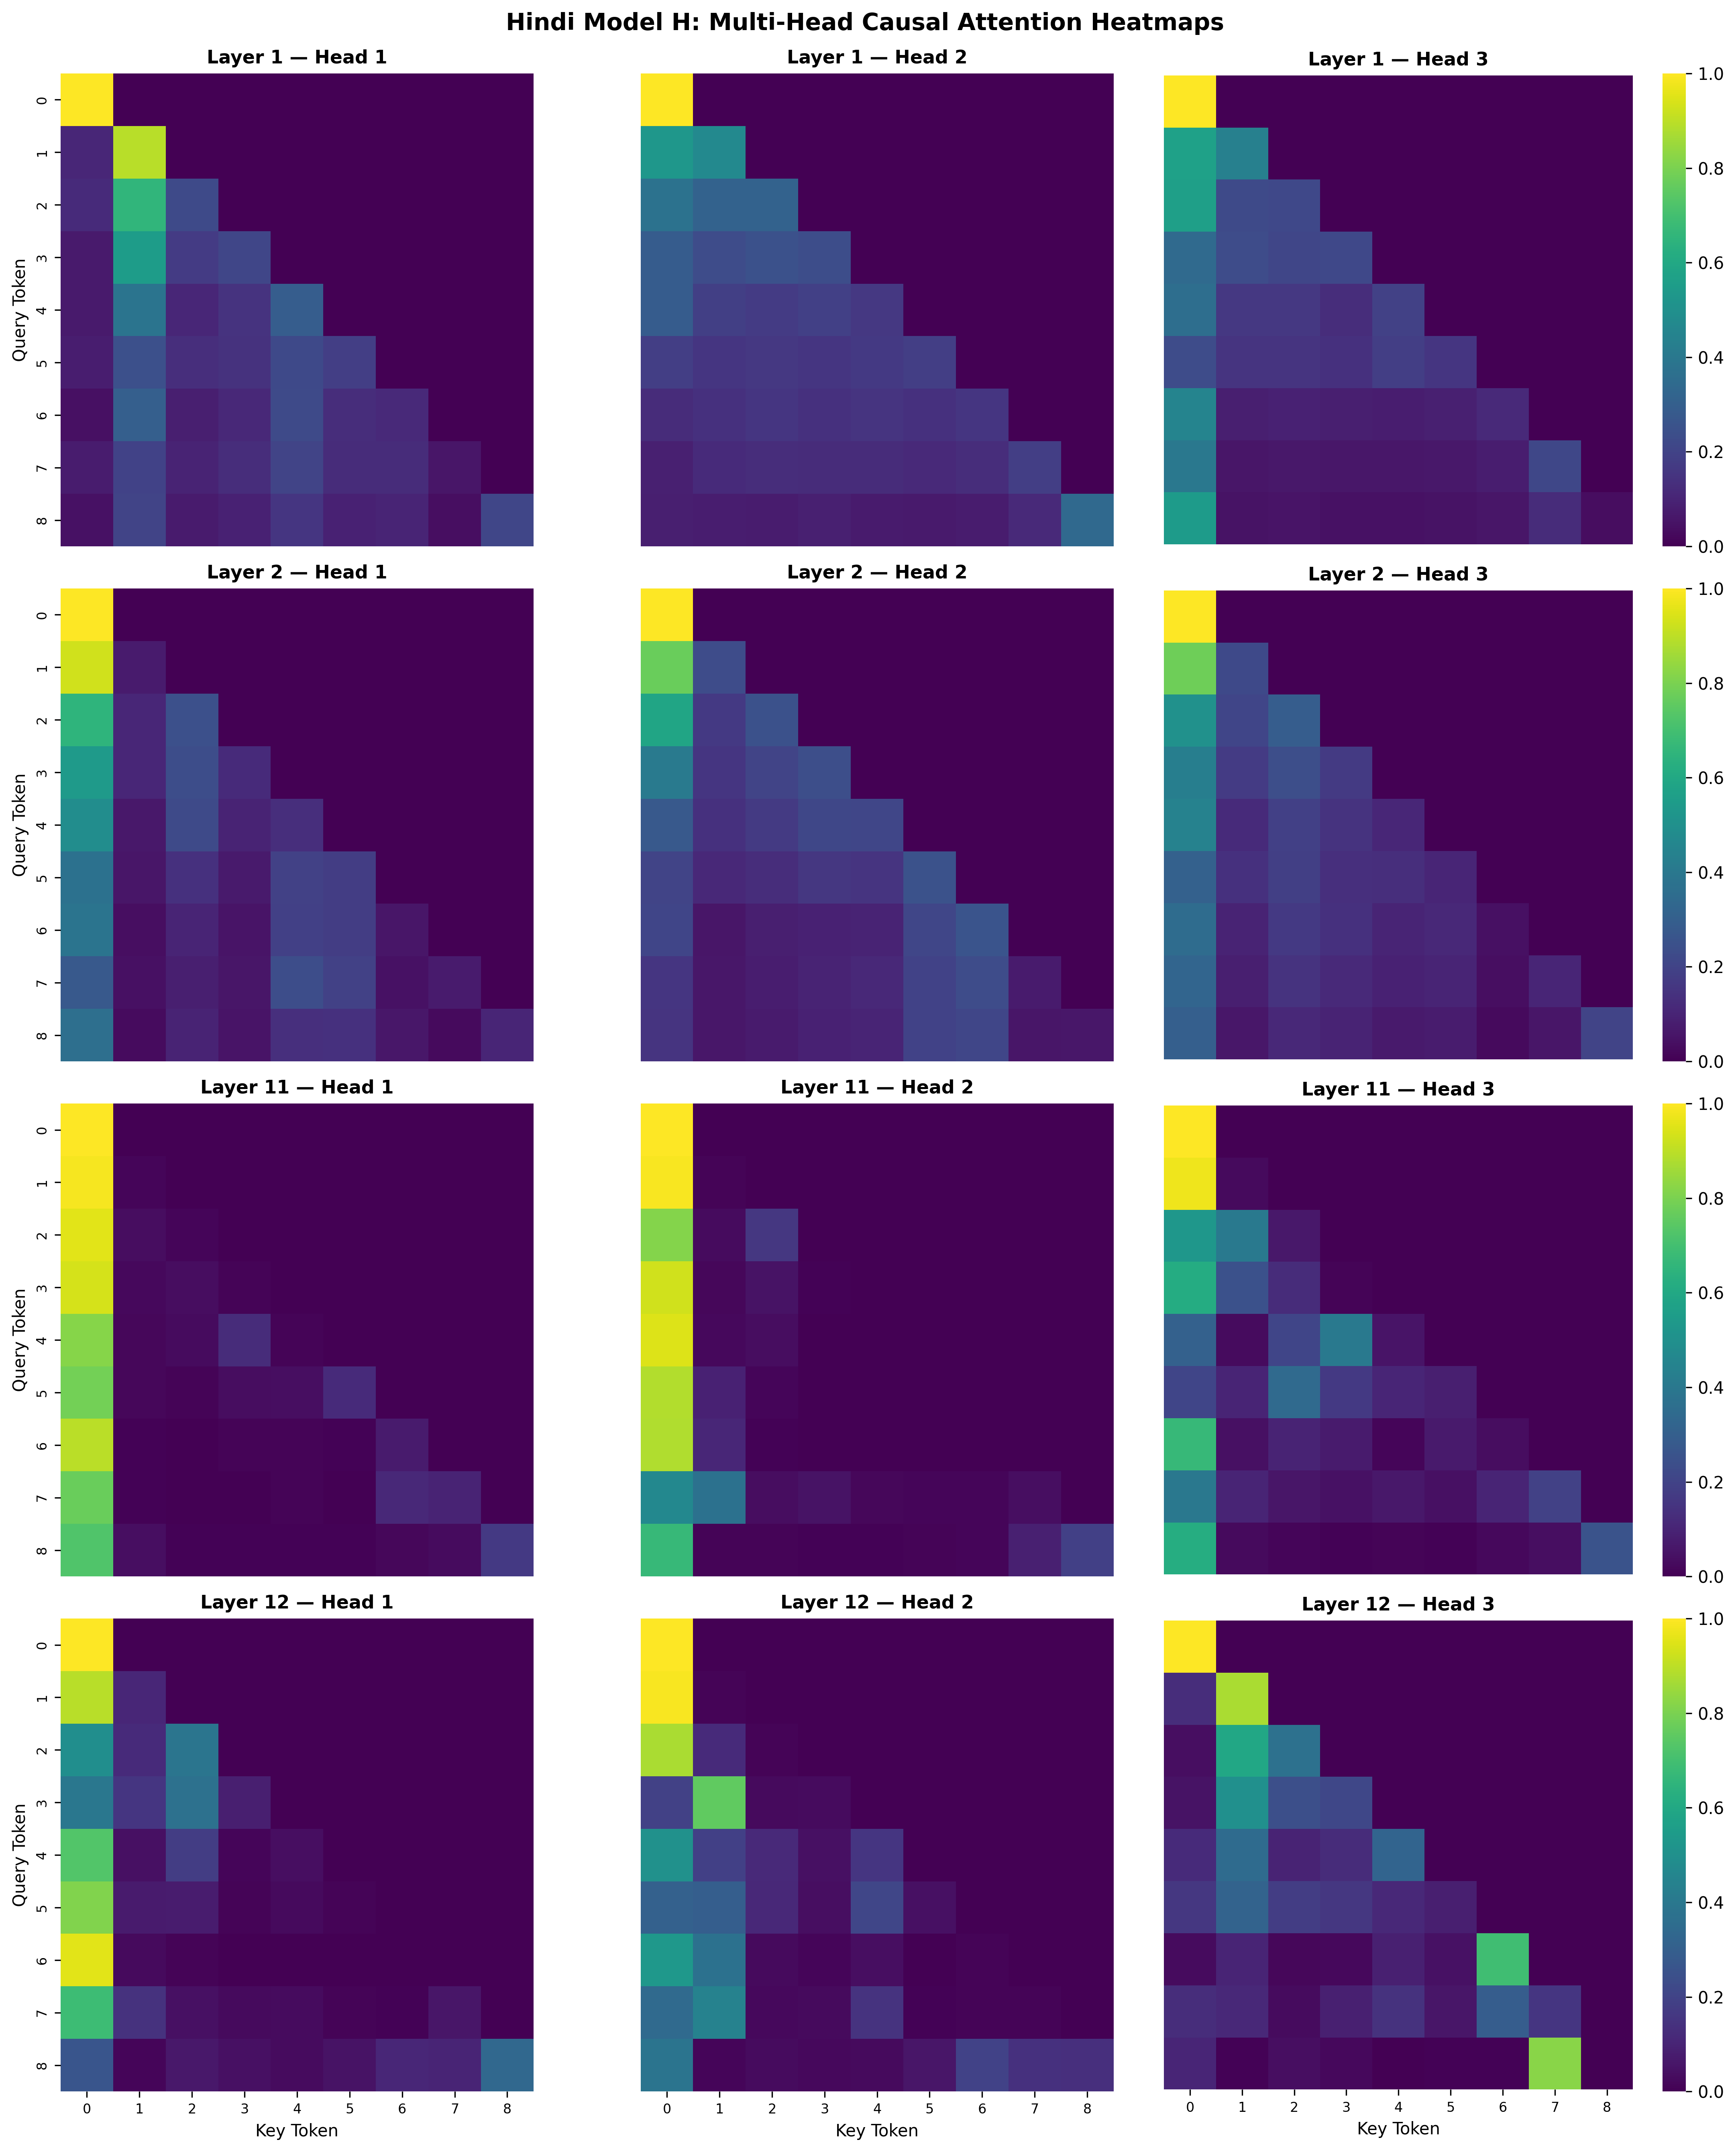


--- HINDI ATTENTION ENTROPY & DISTANCE ---


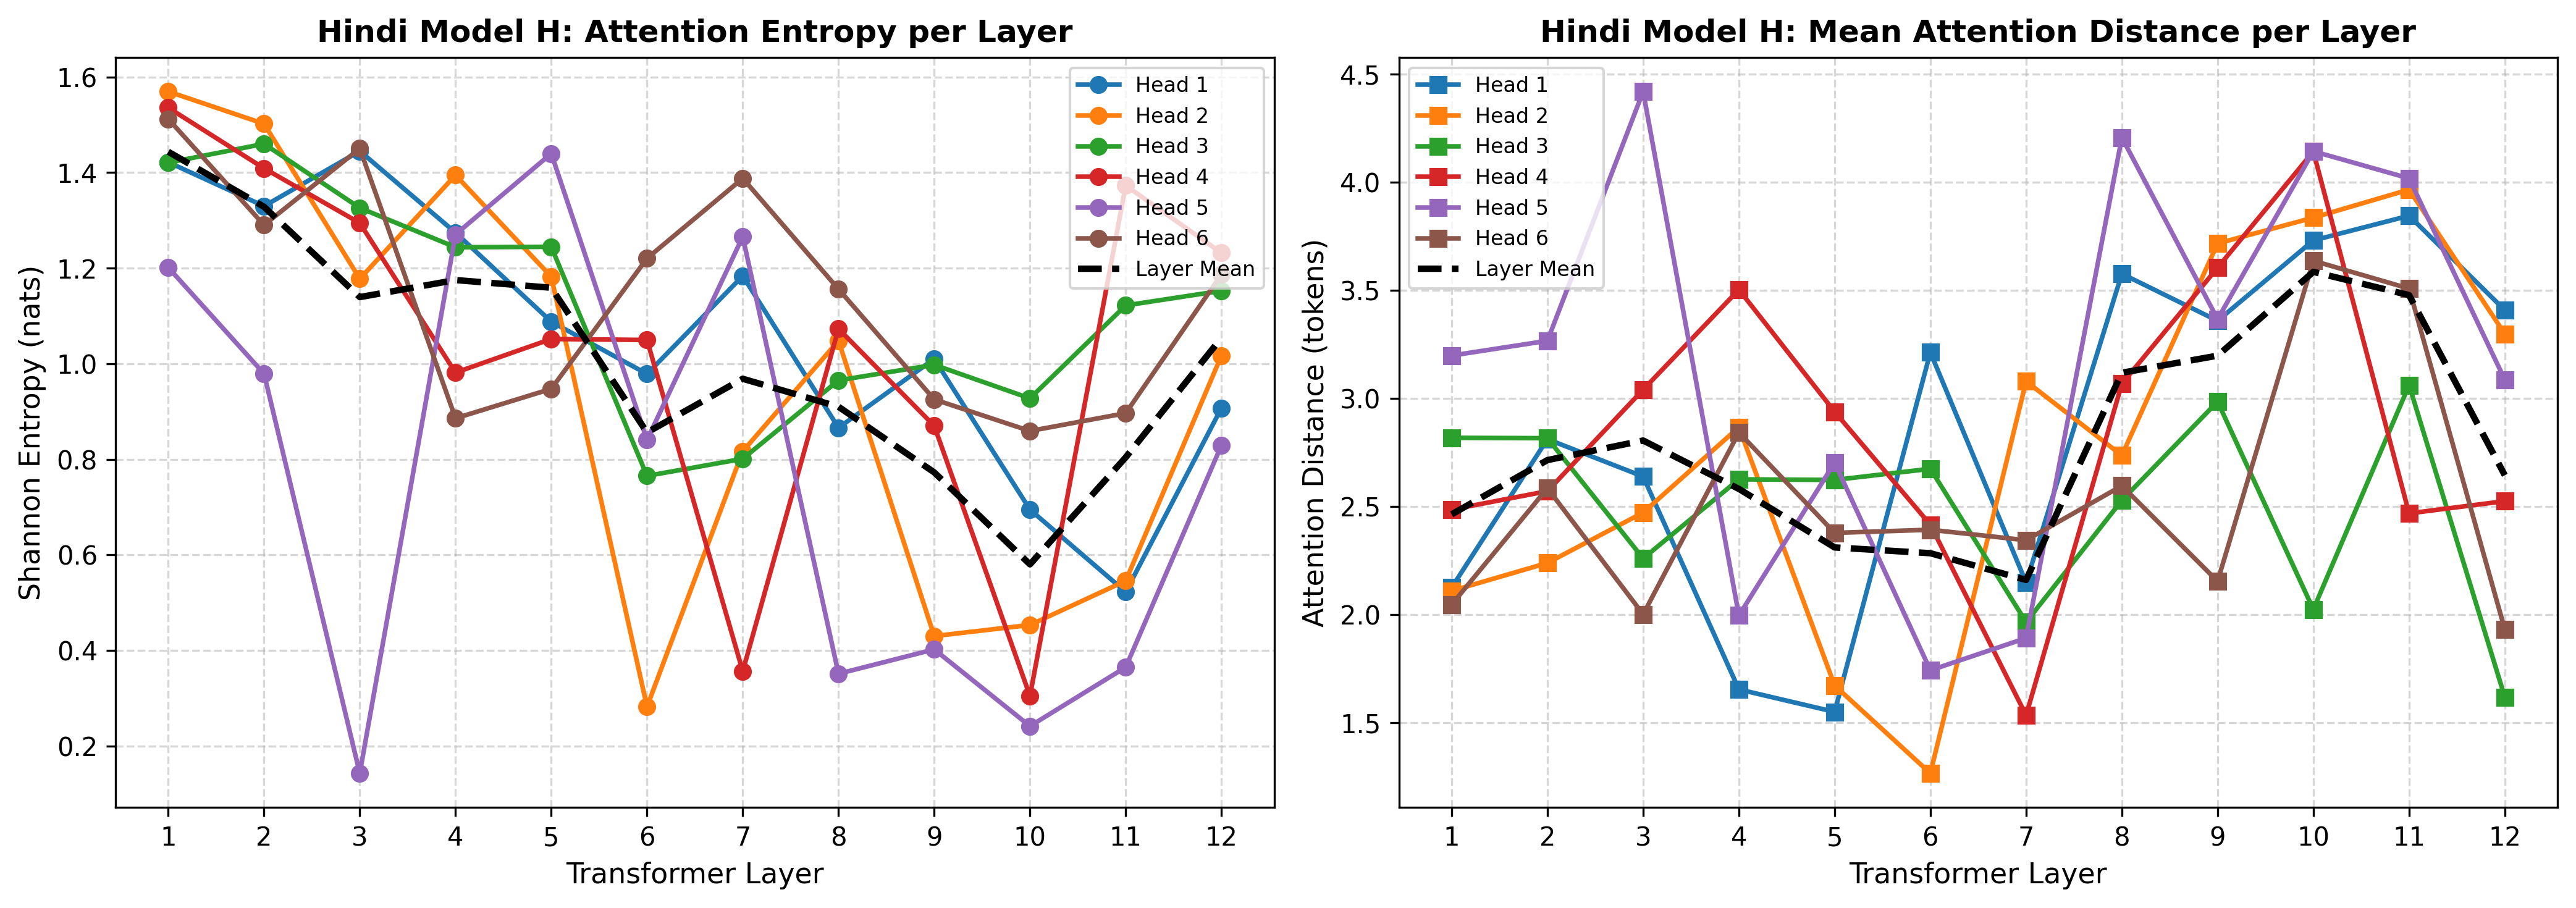

In [10]:
# CELL 9 — HINDI ATTENTION ANALYSIS & HEATMAPS

import os
import shutil
from IPython.display import Image, display

SCRIPT = "/kaggle/working/hindi/eval/attention_analysis.py"
ATTENTION_DIR = "/kaggle/working/hindi/eval/attention"

# 1. Ensure numeric token labels are used

with open(SCRIPT, "r", encoding="utf-8") as f:
    lines = f.readlines()

for i, line in enumerate(lines):

    if "xticklabels=clean_tokens" in line:
        lines[i] = line.replace(
            "xticklabels=clean_tokens",
            "xticklabels=[str(i) for i in range(len(clean_tokens))]"
        )

    if "yticklabels=clean_tokens" in line:
        lines[i] = line.replace(
            "yticklabels=clean_tokens",
            "yticklabels=[str(i) for i in range(len(clean_tokens))]"
        )

with open(SCRIPT, "w", encoding="utf-8") as f:
    f.writelines(lines)


# 2. Run Hindi attention analysis

!python /kaggle/working/hindi/eval/attention_analysis.py \
    --checkpoint /kaggle/working/hindi_checkpoints/checkpoints/checkpoint_best.pt \
    --config_file /kaggle/working/hindi/configs/model_config.json \
    --tokenizer_model /kaggle/working/hindi/tokenizer/unigram_10k/tokenizer.model \
    --output_dir /kaggle/working/hindi/eval/attention \
    --sentence "हिंदी भारत की प्रमुख भाषाओं में से एक है।"

# 3. Check generated files

heatmap = "/kaggle/working/hindi/eval/attention/hindi_attention_heatmaps.png"
entropy = "/kaggle/working/hindi/eval/attention/hindi_attention_entropy_distance.png"

print("\n============================================================")
print("HINDI ATTENTION ANALYSIS COMPLETE")
print("============================================================")

print("\nGenerated files:")
print("Heatmaps :", os.path.exists(heatmap))
print("Entropy  :", os.path.exists(entropy))

# 5. Display graphs directly in Kaggle

if os.path.exists(heatmap):
    print("\n--- HINDI ATTENTION HEATMAPS ---")
    display(Image(filename=heatmap))

if os.path.exists(entropy):
    print("\n--- HINDI ATTENTION ENTROPY & DISTANCE ---")
    display(Image(filename=entropy))


In [ ]:
# CELL 10 — ZIP HINDI TRAINING ARTIFACTS

import os
import shutil

SOURCE_DIR = "/kaggle/working/hindi_checkpoints"
ZIP_PATH = "/kaggle/working/hindi_checkpoints.zip"

print("=" * 60)
print("ZIPPING HINDI TRAINING ARTIFACTS")
print("=" * 60)

if not os.path.exists(SOURCE_DIR):
    raise FileNotFoundError(
        f"Training output directory not found:\n{SOURCE_DIR}"
    )

# Remove old ZIP if it exists
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)
    print("Removed previous ZIP file.")

# Create ZIP
shutil.make_archive(
    "/kaggle/working/hindi_checkpoints",
    "zip",
    "/kaggle/working",
    "hindi_checkpoints"
)

print("\nZIP created:", os.path.exists(ZIP_PATH))

if os.path.exists(ZIP_PATH):
    size_gb = os.path.getsize(ZIP_PATH) / (1024 ** 3)
    print(f"Size: {size_gb:.2f} GB")

print("\nFinal file:")
print(ZIP_PATH)

print("=" * 60)
print("HINDI TRAINING ARTIFACTS PACKAGING COMPLETE")
print("=" * 60)

ZIPPING HINDI TRAINING ARTIFACTS
